# Foundations: is this strawberry purée?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/01_Foundations/notebooks/TD1_strawberry_student.ipynb)

**A guided practical for students who do not program | About 60 minutes**

A supplier claims that a fruit purée is strawberry. We have laboratory
measurements from samples labelled Strawberry and NON-Strawberry. We will
teach a small decision tree to recognise these two labels.

This is **classification**: choosing between the two recorded classes.
We start with one small tree; Evaluation will ask how to compare models.

**All code is supplied.** Run the cells from top to bottom with their ▶
buttons. Read the explanation above each cell and inspect its output.
Leave the code unchanged. To answer a question, double-click the
**Your answer** text cell and write in words.

Click **Open in Colab** above to start this notebook.
Use the standard CPU runtime; no GPU is needed.
Each notebook runs on its own, so run its loading cells even if you have
completed an earlier practical. Internet access is needed to load the data.

An accuracy of 0.90 means that 90% of the samples were classified correctly.

| Step | Time |
|---|---:|
| Understand the data and eight features | 15 min |
| Separate training and test samples | 10 min |
| Fit and read a small decision tree | 15 min |
| Read predictions and mistakes | 15 min |
| Write the conclusion | 5 min |

## 1. Load the strawberry measurements

These cells prepare the same data in all three practicals. The first
cell loads the tools: `pd` works with tables and `plt` draws plots.
A name before `=` stores a result for later use.
Read each cell for its purpose; you do not need to memorise Python syntax.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

This cell reads the public data file. Internet access is needed in Colab.
The fixed address makes all three practicals use the same version.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/zwbben/SpectroscopyData/"
    "4db9b8168fac1185973d1e7888d51f7f33f94857/MIR_Fruit_purees.csv"
)
raw_data = pd.read_csv(DATA_URL, header=None)

The source file has labels across the top and one spectrum in each
column. These three lines separate the labels and turn the measurements
into a table with **one recorded spectrum per row**. Here `iloc` selects
positions, `.T` swaps rows and columns, and `astype(float)` reads the
signals as numbers. This is data preparation, not model training.

A **reference label** is the class recorded in this dataset. Strawberry
is one class; NON-Strawberry includes other fruit purées and adulterated
strawberry mixtures. The file does not identify which kind for each sample.

In [3]:
labels = raw_data.iloc[0, 1:]
spectra = raw_data.iloc[1:, 1:].astype(float).T
spectra.columns = raw_data.iloc[1:, 0].astype(float)

Two records have exactly the same measurements but opposite labels.
We leave both out because this file cannot tell us which label is right.
The `~` sign means “not”: keep the rows that are not repeated.
This leaves 981 recorded spectra: 350 Strawberry and 631 NON-Strawberry.

In [4]:
repeated = spectra.duplicated(keep=False)
spectra = spectra.loc[~repeated]
labels = labels.loc[~repeated]
print("Samples kept:", len(spectra))
print(labels.value_counts())

Samples kept: 981
0
NON-Strawberry    631
Strawberry        350
Name: count, dtype: int64


### Use eight numbers for each sample

Each **feature** is an average signal in a fixed part of the spectrum.
We use the same eight parts in all three practicals. For example, B1 is
the mean signal from 899 to 1012 cm⁻¹. It is not a sugar concentration.

In each line below, `loc` selects a range and `mean(axis=1)` averages
that range for each sample. All eight lines do the same thing with a
different range. `head()` shows the first five rows; `round(4)` rounds
only the display, not the values used by the models.
Row numbers identify positions in this file, not physical specimens.

In [5]:
features = pd.DataFrame(index=spectra.index)
features["B1"] = spectra.loc[:, 899:1012].mean(axis=1)
features["B2"] = spectra.loc[:, 1012:1125].mean(axis=1)
features["B3"] = spectra.loc[:, 1125:1238].mean(axis=1)
features["B4"] = spectra.loc[:, 1238:1351].mean(axis=1)
features["B5"] = spectra.loc[:, 1351:1464].mean(axis=1)
features["B6"] = spectra.loc[:, 1464:1577].mean(axis=1)
features["B7"] = spectra.loc[:, 1577:1690].mean(axis=1)
features["B8"] = spectra.loc[:, 1690:1803].mean(axis=1)
features.head().round(4)

,B1,B2,B3,B4,B5,B6,B7,B8
1,0.0035,0.0097,0.0052,0.0051,0.0049,0.0019,0.0020,0.0019
2,0.0046,0.0149,0.0052,0.0043,0.0047,0.0006,-0.0003,0.0002
3,0.0041,0.0098,0.0050,0.0048,0.0047,0.0019,0.0022,0.0017
4,0.0037,0.0107,0.0055,0.0052,0.0045,0.0009,0.0015,0.0022
5,0.0038,0.0104,0.0057,0.0053,0.0044,0.0008,0.0012,0.0024


### Stop and explain 1

What are the model's inputs, and what label should it predict? Explain
what one value in the B1 column means.

**Your answer:**

*Write your answer here in words.*

## 2. Keep some samples for testing

**Training samples** are the examples the model learns from. **Test samples**
are kept aside to see how it performs on samples excluded from training.

This cell keeps 80% for training and 20% for testing. `stratify=labels`
keeps similar class proportions in both parts. `random_state=42` makes the
split repeatable. Keep these settings unchanged throughout the exercise.

In the code, **X** means the eight feature columns and **y** means the
recorded labels. The endings `_train` and `_test` tell us
which sample group a table belongs to.

This gives 784 training samples and 197 test samples.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 784
Test samples: 197


### Stop and explain 2

Why should the model be tested on samples that it did not learn from?

**Your answer:**

*Write your answer here in words.*

## 3. Teach a small decision tree

A decision tree asks questions such as “is B6 below this value?”
`max_depth=2` allows at most two questions along a path. This setting is
fixed in advance; we are not searching for the best model here.

The first line creates the model. `fit` teaches it from the training features
and their known labels. It does not use the test samples.

In [7]:
tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

Read the tree from the top. If a condition is true, follow the left branch;
otherwise follow the right branch. A final box gives the predicted class.
`samples` is the number of training examples reaching a box. `value` lists
their counts in the order [NON-Strawberry, Strawberry].

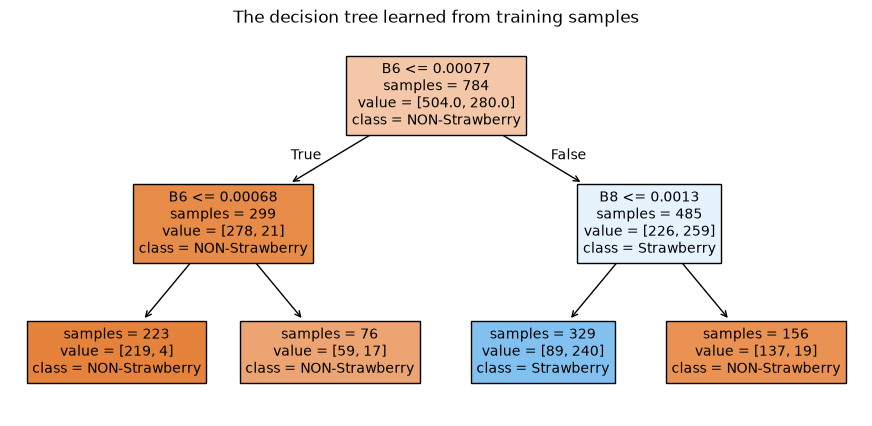

In [8]:
plt.figure(figsize=(11, 5))
plot_tree(tree, feature_names=features.columns,
          class_names=["NON-Strawberry", "Strawberry"],
          filled=True, impurity=False, precision=5, fontsize=10)
plt.title("The decision tree learned from training samples")
plt.show()

### Stop and explain 3

Read the first question in the tree. Which feature does it use, and which
branch does a smaller value follow? Does every final box contain only one class?

**Your answer:**

*Write your answer here in words.*

## 4. Make predictions on the test samples

`predict` applies the learned rules to the test features. The table below
places each prediction next to the reference label. The test labels are
used to check predictions, not to teach the model.

In [9]:
predictions = tree.predict(X_test)
prediction_table = pd.DataFrame({"Reference": y_test, "Prediction": predictions})
prediction_table.head()

,Reference,Prediction
553,Strawberry,Strawberry
940,NON-Strawberry,NON-Strawberry
452,Strawberry,Strawberry
76,Strawberry,Strawberry
155,NON-Strawberry,NON-Strawberry


**Accuracy** is the fraction of predictions that match the reference labels.
A useful comparison is a rule that ignores all measurements and always
predicts the most common training label. Here that label is NON-Strawberry.

In the comparison rule, `==` checks whether a label matches NON-Strawberry;
`mean()` gives the fraction of matching labels.

In [10]:
tree_accuracy = accuracy_score(y_test, predictions)
baseline_accuracy = (y_test == "NON-Strawberry").mean()
print("Always predict NON-Strawberry:", round(baseline_accuracy, 3))
print("Small decision tree:", round(tree_accuracy, 3))

Always predict NON-Strawberry: 0.645
Small decision tree: 0.883


### Stop and explain 4

Does the tree perform better than always predicting NON-Strawberry?
Quote both accuracies. Why is 100% accuracy not a sensible promise for new samples?

**Your answer:**

*Write your answer here in words.*

## 5. Look at the mistakes

This table of counts is a **confusion matrix**. Rows show the reference
labels; columns show predictions. The diagonal contains correct predictions.
The other two boxes contain mistakes.

A NON-Strawberry sample predicted Strawberry is a **false acceptance**.
A Strawberry sample predicted NON-Strawberry is a **false rejection**.

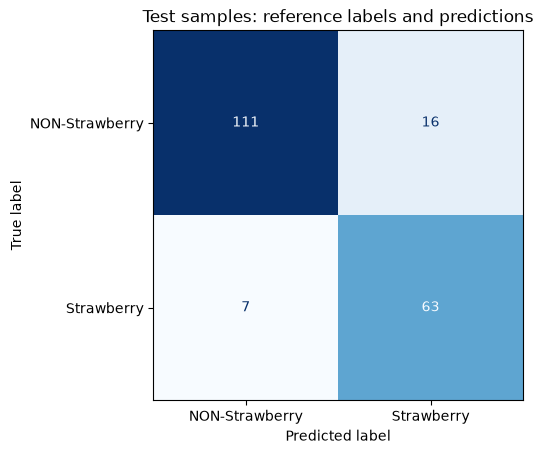

In [11]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["NON-Strawberry", "Strawberry"],
    cmap="Blues", colorbar=False
)
plt.title("Test samples: reference labels and predictions")
plt.show()

### Stop and explain 5

How many false acceptances and false rejections are shown? Give one
practical consequence of each for a laboratory checking incoming products.

**Your answer:**

*Write your answer here in words.*

## 6. Explain the result

The model has learned a few rules from eight measurements and applied them
to excluded samples. Its prediction concerns the two labels in this dataset.
It cannot identify which adulterant is present or prove that a sample is pure.

Next, Evaluation keeps the same features and test group, but sets aside
some training samples to help choose between models.

### Stop and explain 6

Write three sentences for the laboratory manager: what the model predicts,
how well it performed, and one reason to check it on new samples before use.

**Your answer:**

*Write your answer here in words.*

## Data and reuse

The dataset contains measured infrared spectra of fruit purées. The
original file has 983 spectra; 981 remain after excluding the conflicting
pair. NON-Strawberry includes other fruits and adulterated mixtures.
The file does not give separate adulterant, supplier or replicate IDs.
These exercises cannot establish product purity or identify an adulterant.

- Holland, Kemsley and Wilson (1998), *Use of Fourier transform infrared
  spectroscopy and partial least squares regression for the detection of
  adulteration of strawberry purées*.
  [Original study](https://research-portal.uea.ac.uk/en/publications/use-of-fourier-transform-infrared-spectroscopy-and-partial-least-/).
- Shu, Tang, Zhang and Zheng (2019),
  [dataset deposition](https://doi.org/10.17632/frrv2yd9rg.1), version 1.
  Data licence: [CC BY-NC 3.0](https://creativecommons.org/licenses/by-nc/3.0/).
  The data licence is separate from the course-code licence.

The fixed spectral windows are teaching summaries, not selected chemical
markers. This exercise does not reproduce the original paper's analysis.